Batch access of all dataset (glider)
===

## Packages used
To use python to access the ERDDAP server directly from your python script or jupyter-notebook, you will need
- ERDDAPY
- Xarray
- netcdf4 
- matplotlib
- plotly

```{note}
The package [**netcdf4**](http://unidata.github.io/netcdf4-python/) develop by UNIDATA is not needed in the import part of the python script. However, it is the essential package that [support netCDF format output from Xarray](https://docs.xarray.dev/en/stable/user-guide/io.html). The package [**matplotlib**](https://matplotlib.org/stable/) is also not needed in the import part of the python script. It is the essential package that [support quick visualization from Xarray](https://docs.xarray.dev/en/stable/user-guide/plotting.html). 
```

In this page, we demonstrate how to extract/download all data directly on a ERDDAP server and perform data processing, visualization, and export data in python environment. 

```{tip}
[Understanding of the ERDDAP server and what it provides](erddapData) is highly recommended before reading the following intructions.
```

## Import python packages

In [1]:
# cell block designed for colab specifically
#  try import needed package
#  if failed pip install package is performed

try:
    from erddapy import ERDDAP
except ModuleNotFoundError:
    print('ModuleNotFoundError: ERDDAP')
    !pip install erddapy
try:
    import netCDF4
except ModuleNotFoundError:
    print('ModuleNotFoundError: netcdf4')
    !pip install netcdf4

In [2]:
import xarray as xr
from erddapy import ERDDAP

- [**xarray**](https://docs.xarray.dev/en/stable/getting-started-guide/why-xarray.html) is used for data processing and netCDF file output. 
- [**erddapy**](https://ioos.github.io/erddapy/00-quick_intro-output.html) is used to access the ERDDAP server.

Both package-webpages have more detail explanation on its full range of functionalities. 
Here we will mainly focusing on getting the data to be displayer and downloaded.


## Access Glider (TableDAP) data
In this demostration, we will be getting the glider data from [IOOS Glider Data Archived Center](https://gliders.ioos.us/erddap/tabledap/allDatasets.html)

Firstly, the way to use the **erddapy** is to setup the destination ERDDAP server as an object in python through `ERDDAP` ([a python class](https://docs.python.org/3/tutorial/classes.html))

In [3]:
#### access the ERDDAP server 
e = ERDDAP(
    server="https://gliders.ioos.us/erddap/",             # The URL that the ERDDAP server has
    protocol="tabledap",                                  # The data type (griddap or tabledap)
    response="opendap",                                   # different output data type that provided by ERDDAP server       
)

By executing the above code block, we have already setup the connection with the desired ERDDAP server. 
To request a the dataset list on the server, we need to set the `dataset_id = allDatasets`(e.g. https://gliders.ioos.us/erddap/tabledap/allDatasets.html).

To set the `dataset_id`, execute

In [4]:
# set the dataset id name 
#  ex:  https://coastwatch.pfeg.noaa.gov/erddap/griddap/jplAquariusSSS3MonthV5.html
#  dataset_id = jplAquariusSSS3MonthV5
e.dataset_id = "allDatasets"

## Download data list
Now, all the setting for downloading the data list is complete. By executing the following, we convert the list into a pandas dataframe object that contain all the dataset info on the ERDDAP server

In [5]:
df = e.to_pandas()

Let's take a peak at the first five glider deployment

In [6]:
df.head(5)

,datasetID,accessible,institution,dataStructure,cdm_data_type,class,title,minLongitude (degrees_east),maxLongitude (degrees_east),longitudeSpacing (degrees_east),...,fgdc,iso19115,metadata,sourceUrl,infoUrl,rss,email,testOutOfDate,outOfDate,summary
0,allDatasets,public,IOOS Glider DAC,table,Other,EDDTableFromAllDatasets,* The List of All Active Datasets in this ERDD...,NaN,NaN,NaN,...,NaN,NaN,https://gliders.ioos.us/erddap/info/allDataset...,https://gliders.ioos.us/erddap,https://gliders.ioos.us/erddap,https://gliders.ioos.us/erddap/rss/allDatasets...,https://gliders.ioos.us/erddap/subscriptions/a...,NaN,NaN,This dataset is a table which has a row of inf...
1,amelia-20180501T0000,public,Virginia Institute of Marine Science - William...,table,TrajectoryProfile,EDDTableFromNcFiles,amelia-20180501T0000,-75.079579,-74.445788,NaN,...,https://gliders.ioos.us/erddap/metadata/fgdc/x...,https://gliders.ioos.us/erddap/metadata/iso191...,https://gliders.ioos.us/erddap/info/amelia-201...,(local files),https://gliders.ioos.us/erddap/,https://gliders.ioos.us/erddap/rss/amelia-2018...,https://gliders.ioos.us/erddap/subscriptions/a...,NaN,NaN,This is a test mission for the Northwest Passa...
2,amelia-20200825T1929,public,Virginia Institute of Marine Science - William...,table,TrajectoryProfile,EDDTableFromNcFiles,amelia-20200825T1929,-75.360315,-74.443807,NaN,...,https://gliders.ioos.us/erddap/metadata/fgdc/x...,https://gliders.ioos.us/erddap/metadata/iso191...,https://gliders.ioos.us/erddap/info/amelia-202...,(local files),https://gliders.ioos.us/erddap/,https://gliders.ioos.us/erddap/rss/amelia-2020...,https://gliders.ioos.us/erddap/subscriptions/a...,NaN,NaN,This project supports the deployment and realt...
3,amelia-20201015T1436,public,Virginia Institute of Marine Science - William...,table,TrajectoryProfile,EDDTableFromNcFiles,amelia-20201015T1436,-74.947858,-74.405013,NaN,...,https://gliders.ioos.us/erddap/metadata/fgdc/x...,https://gliders.ioos.us/erddap/metadata/iso191...,https://gliders.ioos.us/erddap/info/amelia-202...,(local files),https://gliders.ioos.us/erddap/,https://gliders.ioos.us/erddap/rss/amelia-2020...,https://gliders.ioos.us/erddap/subscriptions/a...,NaN,NaN,This project supports the deployment and realt...
4,amlr01-20181216T0641-delayed,public,NOAA SWFSC Antarctic Ecosystem Research Division,table,TrajectoryProfile,EDDTableFromNcFiles,amlr01-20181216T0641-delayed,-61.756371,-56.996472,NaN,...,https://gliders.ioos.us/erddap/metadata/fgdc/x...,https://gliders.ioos.us/erddap/metadata/iso191...,https://gliders.ioos.us/erddap/info/amlr01-201...,(local files),https://gliders.ioos.us/erddap/,https://gliders.ioos.us/erddap/rss/amlr01-2018...,https://gliders.ioos.us/erddap/subscriptions/a...,NaN,NaN,These data are part of the U.S. Antarctic Mari...


Now, let us create a list of dataset_id. This helps if user want to download all datasets on the server.

In [7]:
dataset_ids = []
for dataset_id in df['datasetID']:
    if dataset_id != 'allDatasets':
        dataset_ids.append(dataset_id)

The first five dataset_id is shown below.

In [8]:
dataset_ids[:5]

['amelia-20180501T0000',
 'amelia-20200825T1929',
 'amelia-20201015T1436',
 'amlr01-20181216T0641-delayed',
 'amlr01-20191206T0452-delayed']

## Picking one dataset to investigate on the fly

In [9]:
# e.dataset_id = 'ce_311-20190703T1802-delayed'
# e.dataset_id = 'amelia-20201015T1436'
e.dataset_id = 'UW685-20230125T0000'
df = e.to_pandas()
ds = df.to_xarray()

```{note}
Here, we try to extract the data from the server by first converting it into a Pandas dataframe then into a Xarray dataset. A direct `e.to_xarray()` would result in the wrong data structure since it is originally a "table" with no multi-index.

Converting to the xarray helps us to convert into a gridded dataset in the later on preprocessing. But if that is not needed, `ds = df.to_xarray()` is not a necessary step to extract the dataset from the server.
```

To focus on the vertical profile, we first remove row that does not contain the depth value. 

In [10]:
ds_transect = ds.where(ds['depth (m)'].notnull(),drop=True)   # only preserve the profile related data

In [11]:
ds

<xarray.Dataset>
Dimensions:                      (index: 813342)
Coordinates:
  * index                        (index) int64 0 1 2 3 ... 813339 813340 813341
Data variables: (12/49)
    trajectory                   (index) object 'UW685-20230125T0000' ... 'UW...
    wmo_id                       (index) int64 4803976 4803976 ... 4803976
    profile_id                   (index) int64 1 1 1 1 1 ... 1000 1000 1000 1000
    time (UTC)                   (index) object '2023-01-26T20:10:27Z' ... '2...
    latitude (degrees_north)     (index) float64 40.83 40.83 ... 41.05 41.05
    longitude (degrees_east)     (index) float64 -124.4 -124.4 ... -126.9 -126.9
    ...                           ...
    time_uv (UTC)                (index) object '2023-01-26T20:10:37Z' ... '2...
    time_uv_qc                   (index) int64 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
    u (m s-1)                    (index) float64 -0.06249 -0.06249 ... nan nan
    u_qc                         (index) float64 3.0 3.0 3.0 3.0 ... nan nan nan
    v (m s-1)                    (index) float64 -0.00278 -0.00278 ... nan nan
    v_qc                         (index) float64 3.0 3.0 3.0 3.0 ... nan nan nan

In [12]:
ds_transect

<xarray.Dataset>
Dimensions:                      (index: 813342)
Coordinates:
  * index                        (index) int64 0 1 2 3 ... 813339 813340 813341
Data variables: (12/49)
    trajectory                   (index) object 'UW685-20230125T0000' ... 'UW...
    wmo_id                       (index) float64 4.804e+06 ... 4.804e+06
    profile_id                   (index) float64 1.0 1.0 1.0 ... 1e+03 1e+03
    time (UTC)                   (index) object '2023-01-26T20:10:27Z' ... '2...
    latitude (degrees_north)     (index) float64 40.83 40.83 ... 41.05 41.05
    longitude (degrees_east)     (index) float64 -124.4 -124.4 ... -126.9 -126.9
    ...                           ...
    time_uv (UTC)                (index) object '2023-01-26T20:10:37Z' ... '2...
    time_uv_qc                   (index) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    u (m s-1)                    (index) float64 -0.06249 -0.06249 ... nan nan
    u_qc                         (index) float64 3.0 3.0 3.0 3.0 ... nan nan nan
    v (m s-1)                    (index) float64 -0.00278 -0.00278 ... nan nan
    v_qc                         (index) float64 3.0 3.0 3.0 3.0 ... nan nan nan

This imidiately decrease the table from 90984 rows to 39661 rows.

### Creating 3D plotting function
To take a quick look on the glider vertical profile, we construct a plotting function using the matplotlib package which could avoid rewriting the plotting code over and over.

In [13]:
import matplotlib.pyplot as plt

def plot_3d_view(ele_angle=-140,hori_angle=60):
    """
    This function is designed for creating axe object) for plotting the 
    3D scatter plot.

    Parameters
    ----------
    ele_angle : integer
        elevation angle of viewing the 3D scatter plot
    hori_angle : integer
        horizontal angle of viewing the 3D scatter plot
    Returns
    -------
    ax : matplotlib axe object
        the axe object that can apply scatter3D method 

    Raises
    ------
    """
    fig = plt.figure(figsize=(5,5))
    ax = plt.axes([0,0,1.5,1],projection = '3d')
    ax.view_init(ele_angle, hori_angle)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_zlabel('Depth')
    return ax

### Plotting a subset of the dataset and focusing on single variables
- temperature profile along the glider path

In [14]:
ds_part=ds_transect
varname='temperature (Celsius)'
zname='depth (m)'
yname='latitude (degrees_north)'
xname='longitude (degrees_east)'

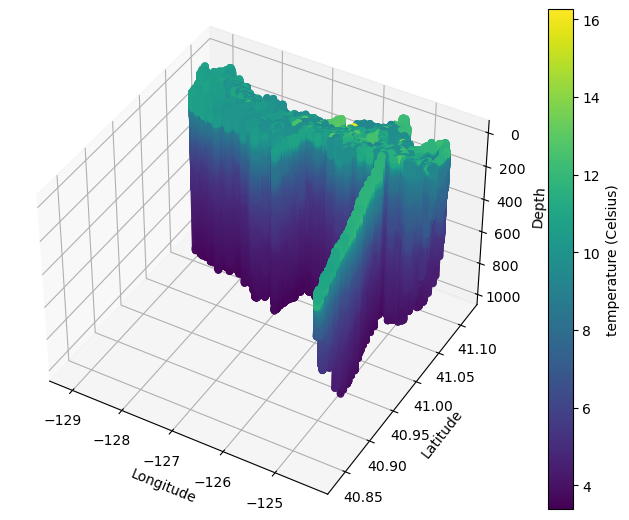

In [15]:
ax2 = plot_3d_view(ele_angle=-140,hori_angle=60)
p = ax2.scatter3D(ds_part[xname],
              ds_part[yname],
              ds_part[zname],
              c=ds_part[varname],      # color value of individual points is taken from their heights
              cmap="viridis"                           # the color mapping to be used. Other example options: winter, autumn, ...
              );
# ax2.invert_zaxis()
ax2.invert_xaxis()
cbar = plt.colorbar(p)
cbar.set_label(varname)


- salinity profile along the glider path

In [16]:
varname='salinity (0.001)'
zname='depth (m)'
yname='latitude (degrees_north)'
xname='longitude (degrees_east)'

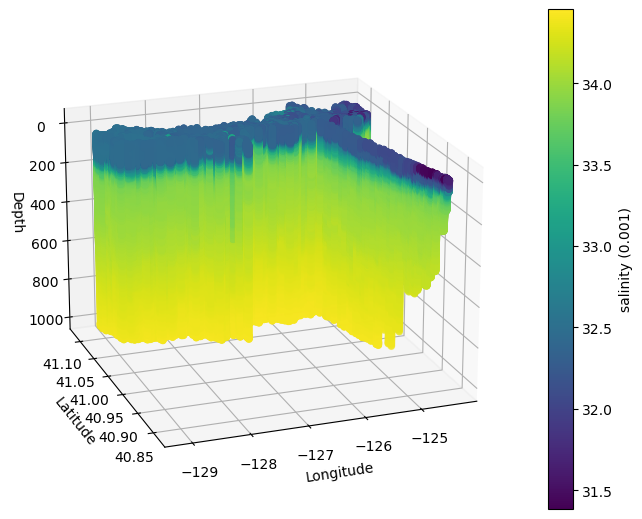

In [17]:
ax2 = plot_3d_view(ele_angle=-160,hori_angle=110)
p = ax2.scatter3D(ds_part[xname],
              ds_part[yname],
              ds_part[zname],
              c=ds_part[varname],      # color value of individual points is taken from their heights
              cmap="viridis"                           # the color mapping to be used. Other example options: winter, autumn, ...
              );
# ax2.invert_zaxis()
ax2.invert_xaxis()
cbar = plt.colorbar(p)
cbar.set_label(varname)

### Showing the geopgraphic location of the glider path

In [18]:
import folium
import numpy as np

lon = ds_part[xname].data
lat = ds_part[yname].data


fmap = folium.Map(location=[(np.min(lat)+np.max(lat))/2, (np.min(lon)+np.max(lon))/2], tiles="OpenStreetMap", zoom_start=8)
points = [[lat[i],lon[i]] for i in range(len(lon)) ]
folium.PolyLine(points, color='red', weight=2.5, opacity=0.4,popup=f'{dataset_id}').add_to(fmap)
folium.Marker([lat[0],lon[0]], popup=f'start').add_to(fmap)
folium.Marker([lat[-1],lon[-1]], popup=f'end').add_to(fmap)
    
fmap

## Converting the table data to gridded data

In [19]:
import numpy as np
import pandas as pd

# idealy/theoretically the three array should have same len (first dimension)
# lat = np.unique(ds_transect['latitude (degrees_north)'].data)
# lon = np.unique(ds_transect['longitude (degrees_east)'].data)
time = np.unique(ds_transect['time (UTC)'].data)
dtime = pd.to_datetime(time)

In [20]:
# vertical profile (second dimension)
depth = np.unique(ds_transect['depth (m)'].data)

In [21]:
# create 2D gridded array for vertical profile along the glider trajectory
da_transect = xr.DataArray(
    coords={
        "depth": depth,
        "time": dtime.values,
        # "lon": ("time", lon),  # place holder not real lon at the associated time
        # "lat": ("time", lat),  # place holder not real lat at the associated time
    },
    dims=["depth", "time"],
)
da_transect = da_transect.rename('var')

In [22]:
len(time)

988

To convert the row data into gridded data, the following process do 
1. for each single time profiling, we take all the vertical measurement
2. for each single time profiling, we mean the measurement on the same vertical level
3. if multiple location is registered during the vertical profiling, we use the first recorded location as the profiling location
4. the veritical profile is linearly interpolated to make every vertical profiling to have the same number of grid

In [23]:
# we minimized the number of time profiling that needed to be processed to gridded data in this notebook (efficiency)
print(f'processing {varname}')
for i in range(len(time[:10])):
    print(time[i])
    loc_time = time[i]
    
    # only preserve single time (mid point time during the profiling)
    ds_temp = ds_transect.where((ds['time (UTC)'] == loc_time),drop=True)
    ds_temp = ds_temp.assign_coords({'depth':ds_temp['depth (m)']})
    
    # group mean the value for up and down profiling (single depth single value)
    ds_temp = ds_temp.groupby('depth (m)').mean()
    
#     loc_lat = np.unique(ds_temp['latitude (degrees_north)'].data)
#     loc_lon = np.unique(ds_temp['longitude (degrees_east)'].data)
#     if (len(loc_lat)>1) | (len(loc_lon)>1) :
#         print('multiple location at a single time (first point used)')
#         da_transect['lon'][i] = loc_lon[0]
#         da_transect['lat'][i] = loc_lat[0]
#     else:
#         da_transect['lon'][i] = loc_lon[0]
#         da_transect['lat'][i] = loc_lat[0]
        
    # create profile data array to store profiling at one location
    da_var = xr.DataArray(
        ds_temp[varname].data,
        coords={"depth": ds_temp['depth (m)'].data},
        dims=["depth"]
    )
    da_var = da_var.rename('var')

    # put the single profiling to the 2D gridded dataarray
    da_var = da_var.interp(
        depth=depth,
        method="linear",
        kwargs={"fill_value": np.nan},
    )
    da_transect[:,i] = da_var 
    # da_transect[:,i] = xr.merge([da_transect[:,i],da_var])['var'] # merge help fill in the NaN in missing profiling

processing salinity (0.001)
2023-01-26T20:10:27Z
2023-01-26T20:14:27Z
2023-01-26T20:35:57Z
2023-01-26T20:40:19Z
2023-01-26T21:05:05Z
2023-01-26T21:33:42Z
2023-01-26T22:08:21Z
2023-01-26T22:40:14Z
2023-01-26T23:27:47Z
2023-01-27T00:17:52Z
2023-01-27T01:15:09Z
2023-01-27T02:09:10Z
2023-01-27T03:08:59Z
2023-01-27T03:59:08Z
2023-01-27T04:56:25Z
2023-01-27T05:45:51Z
2023-01-27T06:50:16Z
2023-01-27T08:19:03Z
2023-01-27T09:59:44Z
2023-01-27T11:42:00Z


In [24]:
da_transect

<xarray.DataArray 'var' (depth: 803034, time: 988)>
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])
Coordinates:
  * depth    (depth) float64 -0.3087 -0.3073 -0.3015 ... 993.3 993.4 993.4
  * time     (time) datetime64[ns] 2023-01-26T20:10:27 ... 2023-05-22T11:44:01

## Plotting the gridded data

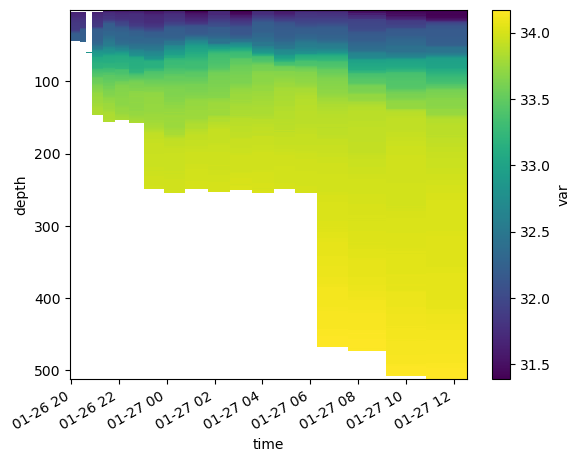

In [25]:
da_transect.where(da_transect.notnull(),drop=True).plot(yincrease=False, x='time', y='depth')